###**1. Libraries**

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
from scipy.fftpack import fft, ifft
import cvxpy as cp

###**2. Exercise**

For $n = 1000$ and $K = 5$, create a $K$-sparse vector $s$ of Fourier coefficients in a Fourier basis $\Psi$.

   (a) For each $p$ from 1 to 100, create a Gaussian random sampling matrix $C \in \mathbb{R}^{p \times n}$ to create a measurement vector $y = C\Psi s$. Use compressed sensing based on this measurement to estimate $\hat{s}$. For each $p$, repeat this with at least 10 realizations of the random measurement matrix $C$. Plot the average relative error of

   $$\frac{\|\hat{s} - s\|_2}{\|s\|}$$

   versus $p$. It may be helpful to visualize the errors with a box-and-whisker plot. Discuss your results.



In [ ]:
#create a K - sparse vector s with length n
def sparse_vector_s(n, K, seed = 2026):

    #create a random number generator object rng
    rng = np.random.default_rng(seed)

    #initial s zero vector
    s = np.zeros(n)

    #select K random index from 0 to n - 1
    idx = rng.choice(n, K, replace=False)
    s[idx] = rng.standard_normal(K)

    return s

#Create a sparsity basis Psi (n x n)
def Psi(n):
  return np.fft.ifft(np.eye(n), axis=0) * np.sqrt(n)

#Create a Gaussian sampling matrix p x n
def sampling_matrix_C(p, n, seed = 2026):
    rng = np.random.default_rng(seed)
    return rng.standard_normal((p, n)) / np.sqrt(p)

def Theta(sampling_matrix_C, Psi):
    return sampling_matrix_C @ Psi

#Create a measurement vector y (p x 1)
def measurement_vector_y(Theta, s):

    #y = C x Psi x s = Theta x s
    return Theta @ s

def relative_error(s_hat, s):
    return np.linalg.norm(s_hat - s) / np.linalg.norm(s)

In [ ]:
#compressed sensing
def sparse_s_min_L1(Theta, measurement_vector_y):
  y = measurement_vector_y
  n = Theta.shape[1]

  # Construct the problem.
  s = cp.Variable(n)                          #variable to be optimized
  objective = cp.Minimize(cp.norm1(s))        #objective function
  constraints = [Theta @ s == y]              #constraint
  problm = cp.Problem(objective, constraints) #creating the cp.Problem object

  #Solving the problem
  problm.solve()

  return s.value

In [ ]:
def ave_rel_errors_K(k, p = 100, N = 1000, rep = 10):
  n = N
  K = k
  trials = rep
  p_values = np.arange(1, p + 1)
  s_exact = sparse_vector_s(n, K)
  s_list = []

  for t in range(trials):
      #Generating the list of measurement vector y
      sampling_matrix_list = [sampling_matrix_C(p, n, seed = 2026 + t) for p in p_values]
      Theta_list = [Theta(sampling_matrix_C, Psi(n)) for sampling_matrix_C in sampling_matrix_list]
      measurement_vector_y_list = [measurement_vector_y(Theta, s_exact) for Theta in Theta_list]        #measurement y vectors
      s_ = [sparse_s_min_L1(Theta, measurement_vector_y) for Theta, measurement_vector_y in zip(Theta_list, measurement_vector_y_list)]
      s_list.append(s_)

  #Creating the boxplot entries
  a = trials
  b = len(s_)
  error_matrix = np.zeros((a, b))

  for i in range(a):
    for j in range(b):
      error_matrix [i, j] = np.linalg.norm(s_list[i][j] - s_exact) / np.linalg.norm(s_exact)

  for_boxplot_error = np.array([error_matrix[:, i] for i in range(b)])

  return for_boxplot_error.T

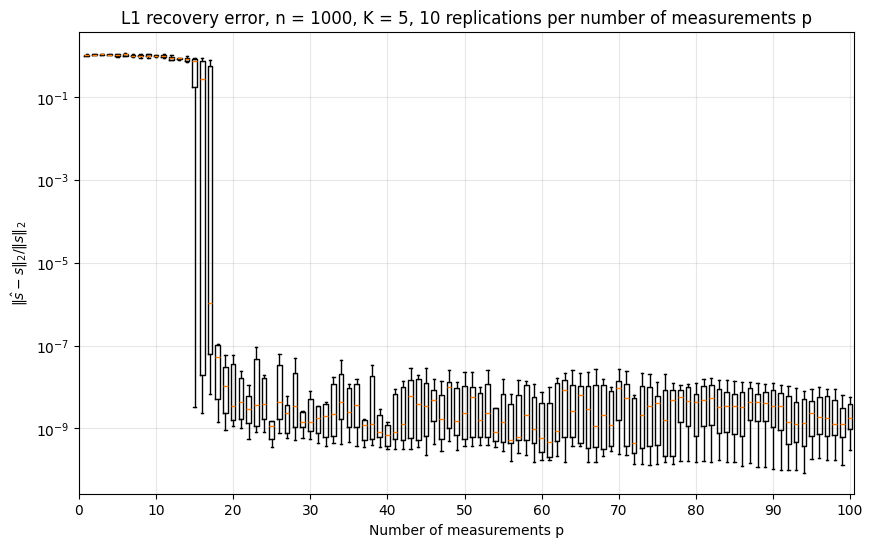

In [ ]:
#plotting
plt.figure(figsize=(10, 6))
relative_err2D = ave_rel_errors_K(k = 5, p = 100, N = 1000, rep = 10)
plt.boxplot(relative_err2D, positions = np.arange(1, 101), widths=0.6, showfliers=False)
plt.yscale("log")
plt.xticks(np.arange(0, 101, 10), np.arange(0, 101, 10))   # label every 10th p
plt.xlabel("Number of measurements p")
plt.ylabel(r"$\|\hat{s}-s\|_2 / \|s\|_2$")
plt.title(f"L1 recovery error, n = 1000, K = 5, 10 replications per number of measurements p")
plt.grid(True, alpha=0.3)
plt.show()
plt.show()

   (b) Repeat (a) for $K = 1$ through 20. Discuss your results.

In [ ]:
error_3D = np.array([ave_rel_errors_K(k = i, p = 100, N = 1000, rep = 10) for i in range(1, 21)])


In [ ]:
Z = np.log10(mean_err + 1e-16)

fig = plt.figure(figsize=(9, 6))
ax = fig.add_subplot(111, projection="3d")
surf = ax.plot_surface(P, KK, Z, cmap="viridis", edgecolor="k", linewidth=0.3)

# Relabel z ticks: position = log10 value, label = 10^k
zmin, zmax = int(np.floor(Z.min())), int(np.ceil(Z.max()))
ticks = np.arange(zmin, zmax + 1)
ax.set_zticks(ticks)
ax.set_zticklabels([rf"$10^{{{t}}}$" for t in ticks])

ax.set_xlabel("Number of measurements p")
ax.set_ylabel("Sparsity K")
ax.set_zlabel(r"$\|\hat{s}-s\|_2 / \|s\|_2$")      # same label as the 2D plot
ax.set_title("L1 recovery error vs p and K")

cbar = fig.colorbar(surf, shrink=0.6, pad=0.1)
cbar.set_ticks(ticks)
cbar.set_ticklabels([rf"$10^{{{t}}}$" for t in ticks])   # colorbar matches

ax.view_init(elev=60, azim=-140)
plt.show()

In [ ]:
mean_err = error_3D.mean(axis=1)               # (K, p): average over trials
Z = np.log10(mean_err + 1e-16)

K_values = np.arange(1, error_3D.shape[0] + 1)
p_values = np.arange(1, error_3D.shape[2] + 1)

fig, ax = plt.subplots(figsize=(9, 5))
mesh = ax.pcolormesh(p_values, K_values, Z, cmap="viridis", shading="nearest")

ax.set_xlabel("Number of measurements p")
ax.set_ylabel("Sparsity K")
ax.set_title("L1 recovery error vs p and K")
ax.set_yticks(K_values)

# Colorbar with 10^k labels (same trick as the 3D plot)
ticks = np.arange(int(np.floor(Z.min())), int(np.ceil(Z.max())) + 1)
cbar = fig.colorbar(mesh, ax=ax)
cbar.set_ticks(ticks)
cbar.set_ticklabels([rf"$10^{{{t}}}$" for t in ticks])
cbar.set_label(r"$\|\hat{s}-s\|_2 / \|s\|_2$")

plt.show()

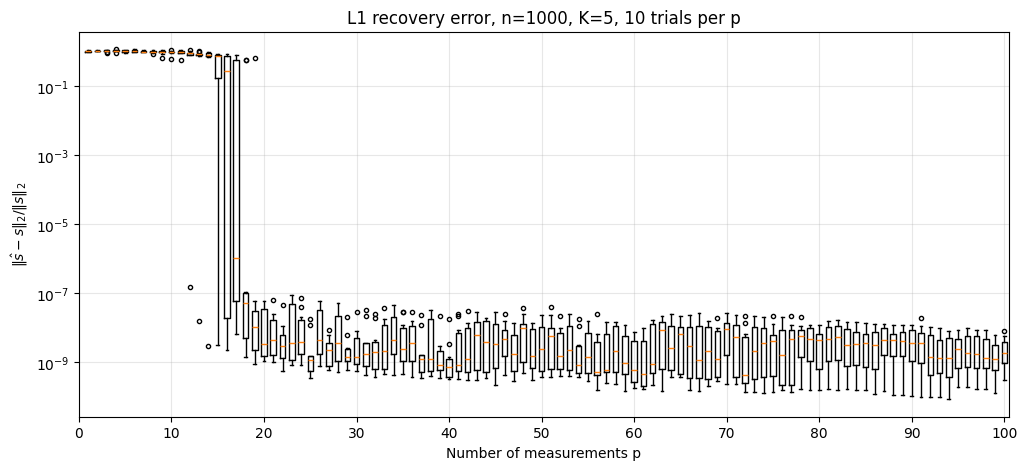

In [ ]:
plot_K(5)

In [ ]:
def plot_K(k):
  n = 1000
  K = k
  trials = 10
  p_values = np.arange(1, 101)
  s_exact = sparse_vector_s(n, K)
  s_list = []

  for t in range(trials):
      #Generating the list of measurement vector y
      sampling_matrix_list = [sampling_matrix_C(p, n, seed = 2026 + t) for p in p_values]
      Theta_list = [Theta(sampling_matrix_C, Psi(n)) for sampling_matrix_C in sampling_matrix_list]
      measurement_vector_y_list = [measurement_vector_y(Theta, s_exact) for Theta in Theta_list]        #measurement y vectors
      s_ = [sparse_s_min_L1(Theta, measurement_vector_y) for Theta, measurement_vector_y in zip(Theta_list, measurement_vector_y_list)]
      s_list.append(s_)

  #Creating the boxplot entries
  a = trials
  b = len(s_)
  error_matrix = np.zeros((a, b))

  for i in range(a):
    for j in range(b):
      error_matrix [i, j] = np.linalg.norm(s_list[i][j] - s_exact) / np.linalg.norm(s_exact)

  for_boxplot_error = [error_matrix[:, i] for i in range(b)]

###**3. References**

Running Part (a)...


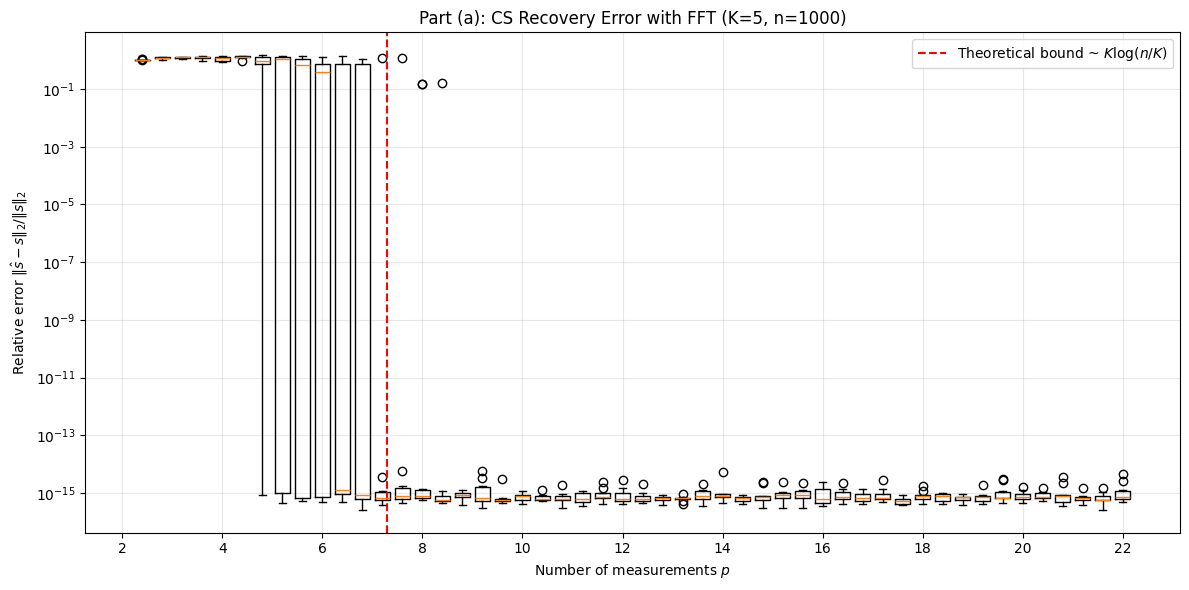

Running Part (b) - This will take slightly longer due to custom complex OMP...


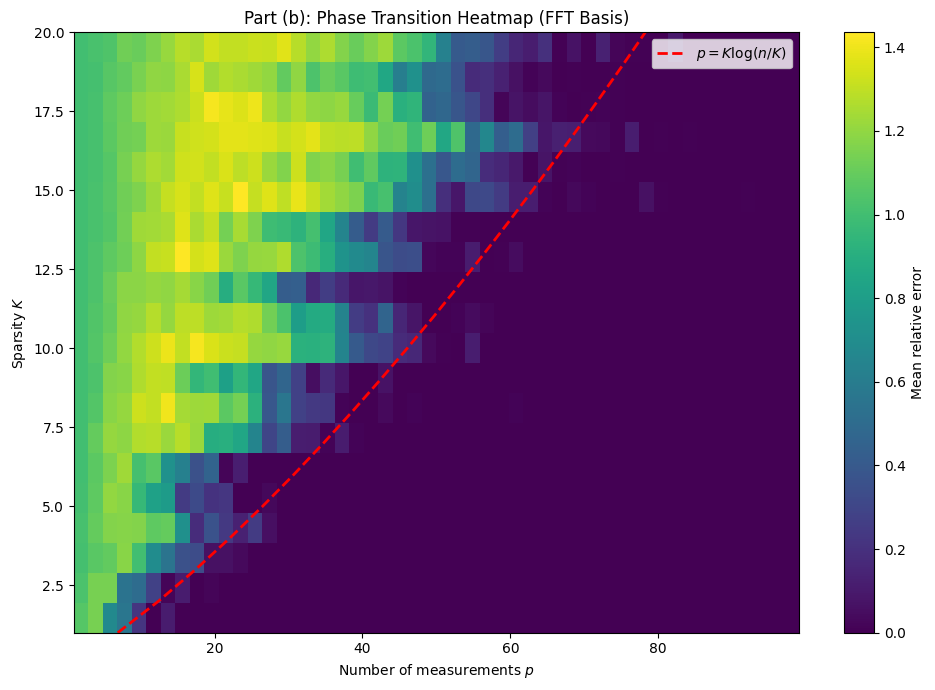

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.fft import fft

# --- 1. Helper Functions ---
def generate_sparse_signal(n, K, rng):
    """Creates a K-sparse complex signal in dimension n."""
    s = np.zeros(n, dtype=complex)
    indices = rng.choice(n, K, replace=False)
    # Fourier coefficients are generally complex
    s[indices] = rng.standard_normal(K) + 1j * rng.standard_normal(K)
    return s

def complex_omp(A, y, K):
    """
    A custom Orthogonal Matching Pursuit (OMP) that handles complex data.
    """
    residual = y.copy()
    idx = []

    for _ in range(K):
        # 1. Match: find the column of A most correlated with the residual
        correlations = np.abs(A.conj().T @ residual)
        best_idx = np.argmax(correlations)
        idx.append(best_idx)

        # 2. Update: solve least squares on the selected columns
        A_subset = A[:, idx]
        x_est, _, _, _ = np.linalg.lstsq(A_subset, y, rcond=None)

        # 3. Calculate new residual
        residual = y - A_subset @ x_est

    # Reconstruct the sparse vector
    s_hat = np.zeros(A.shape[1], dtype=complex)
    s_hat[idx] = x_est
    return s_hat

def relative_error(s_hat, s):
    return np.linalg.norm(s_hat - s) / (np.linalg.norm(s) + 1e-12)

def run_cs_trials(p, n, s_true, Psi, K, rng, n_trials=10):
    """Runs multiple compressed sensing trials for a given p."""
    errors = []
    for _ in range(n_trials):
        # Create Gaussian random sampling matrix (Real)
        C = rng.standard_normal((p, n)) / np.sqrt(p)
        # Measurement matrix (Complex, because Psi is complex)
        A = C @ Psi
        # Measurements
        y = A @ s_true

        s_hat = complex_omp(A, y, K)
        errors.append(relative_error(s_hat, s_true))
    return errors

# --- Setup Shared Parameters ---
n = 1000
n_trials = 10
rng = np.random.default_rng(42)

# Generate the normalized DFT (FFT) matrix
Psi = fft(np.eye(n), norm='ortho')

# ==========================================
# PART (a): Fixed K=5, varying p from 1 to 100
# ==========================================
print("Running Part (a)...")
K_a = 5
p_values_a = np.arange(1, 101)
s_true_a = generate_sparse_signal(n, K_a, rng)

errors_by_p_a = [run_cs_trials(p, n, s_true_a, Psi, K_a, rng, n_trials) for p in p_values_a]

plt.figure(figsize=(12, 6))
plot_p = p_values_a[1::2]
plot_err = errors_by_p_a[1::2]

plt.boxplot(plot_err, positions=plot_p, widths=1.5)
plt.axvline(K_a * np.log(n/K_a), color='r', linestyle='--', label=r'Theoretical bound ~ $K\log(n/K)$')
plt.xlabel('Number of measurements $p$')
plt.ylabel(r'Relative error $\|\hat{s}-s\|_2 / \|s\|_2$')
plt.title(f'Part (a): CS Recovery Error with FFT (K={K_a}, n={n})')
plt.yscale('log')
plt.xticks(np.arange(0, 101, 10))
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

# ==========================================
# PART (b): Varying K from 1 to 20, p from 1 to 100
# ==========================================
print("Running Part (b) - This will take slightly longer due to custom complex OMP...")
K_values_b = np.arange(1, 21)
p_values_b = np.arange(1, 101, 2)
mean_error_grid = np.zeros((len(K_values_b), len(p_values_b)))

for i, K_curr in enumerate(K_values_b):
    s_true_b = generate_sparse_signal(n, K_curr, rng)
    for j, p in enumerate(p_values_b):
        errs = run_cs_trials(p, n, s_true_b, Psi, K_curr, rng, n_trials)
        mean_error_grid[i, j] = np.nanmean(errs)

plt.figure(figsize=(10, 7))
im = plt.imshow(mean_error_grid, aspect='auto', origin='lower',
                extent=[p_values_b[0], p_values_b[-1], K_values_b[0], K_values_b[-1]],
                cmap='viridis')
plt.colorbar(im, label='Mean relative error')

K_arr = np.array(K_values_b)
plt.plot(K_arr * np.log(n/K_arr), K_arr, 'r--', linewidth=2, label=r'$p = K\log(n/K)$')

plt.xlabel('Number of measurements $p$')
plt.ylabel('Sparsity $K$')
plt.title('Part (b): Phase Transition Heatmap (FFT Basis)')
plt.legend()
plt.tight_layout()
plt.show()